In [1]:
# ==============================================================================
# APPROCHE MACHINE LEARNING MULTIDIMENSIONNELLE (K-MEANS 3D) — SENTINEL-2
# Fusion spectrale : dNBR (B08/B12) + dNDVI (B08/B04) + dNBR2 (B11/B12)
# ==============================================================================
# Après avoir étudié l'algorithme K-Means en une seule dimension (dNBR seul),
# ce troisième notebook exploite la pleine puissance du Machine Learning en 
# combinant simultanément 3 dimensions physiques complémentaires de l'incendie :
# 1. dNBR  : Dégradation structurelle de la canopée et exposition du sol nu.
# 2. dNDVI : Perte pure d'activité chlorophyllienne (photosynthèse).
# 3. dNBR2 : Assèchement hydrique et dépôt de charbon/cendres dans le SWIR.
# ==============================================================================

# ------------------------------------------------------------------------------
# ÉTAPE 1 — Importation des bibliothèques et chargement des rasters d'indices
# ------------------------------------------------------------------------------
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Détection automatique de la racine du projet (remonte depuis 'notebooks/')
current_dir = Path.cwd().resolve()
PROJECT_DIR = next((p for p in [current_dir] + list(current_dir.parents) if (p / "src").exists()), current_dir)
OUTPUTS_DIR = PROJECT_DIR / "outputs"

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.indices import SEVERITY_LABELS

def load_output_raster(filename: str):
    filepath = OUTPUTS_DIR / filename
    if not filepath.exists():
        raise FileNotFoundError(
            f"❌ Fichier {filepath} introuvable. "
            f"Exécutez d'abord 'burn_severity_analysis.ipynb' !"
        )
    with rasterio.open(filepath) as src:
        return src.read(1), src.profile

# Chargement des 3 indices spectraux continus (float32) et de la carte USGS (uint8)
dnbr_array, profile = load_output_raster("dnbr.tif")
dndvi_array, _      = load_output_raster("dndvi.tif")
dnbr2_array, _      = load_output_raster("dnbr2.tif")
severity_usgs, _    = load_output_raster("severity.tif")

# Calcul dynamique de la surface exacte d'un pixel via la matrice affine
transform = profile['transform']
pixel_area_m2 = abs(transform.a) * abs(transform.e)

# Palette de couleurs officielle USGS
color_map = {
    0: (34, 139, 34),    # Non brûlé (Unburned)  -> Vert forêt
    1: (255, 255, 0),    # Faible (Low)          -> Jaune
    2: (255, 165, 0),    # Modérée (Moderate)    -> Orange
    3: (255, 0, 0),      # Haute (High)          -> Rouge
    4: (139, 0, 0),      # Très Haute (Very High)-> Rouge foncé
}

print("✅ Les 3 indices spectraux ont été chargés avec succès pour l'analyse 3D :")
print(f"   Dimensions matricielles : {dnbr_array.shape} ({dnbr_array.size:,} pixels)")
print(f"   Plage dNBR              : {dnbr_array.min():.3f} à {dnbr_array.max():.3f}")
print(f"   Plage dNDVI             : {dndvi_array.min():.3f} à {dndvi_array.max():.3f}")
print(f"   Plage dNBR2             : {dnbr2_array.min():.3f} à {dnbr2_array.max():.3f}")

✅ Les 3 indices spectraux ont été chargés avec succès pour l'analyse 3D :
   Dimensions matricielles : (1127, 1185) (1,335,495 pixels)
   Plage dNBR              : -0.800 à 1.343
   Plage dNDVI             : -1.103 à 0.836
   Plage dNBR2             : -0.333 à 0.571


  MATRICE DE CORRÉLATION DE PEARSON ENTRE LES 3 INDICES


,dNBR (B08-B12),dNDVI (B08-B04),dNBR2 (B11-B12)
dNBR (B08-B12),1.000,0.982,0.988
dNDVI (B08-B04),0.982,1.000,0.966
dNBR2 (B11-B12),0.988,0.966,1.000


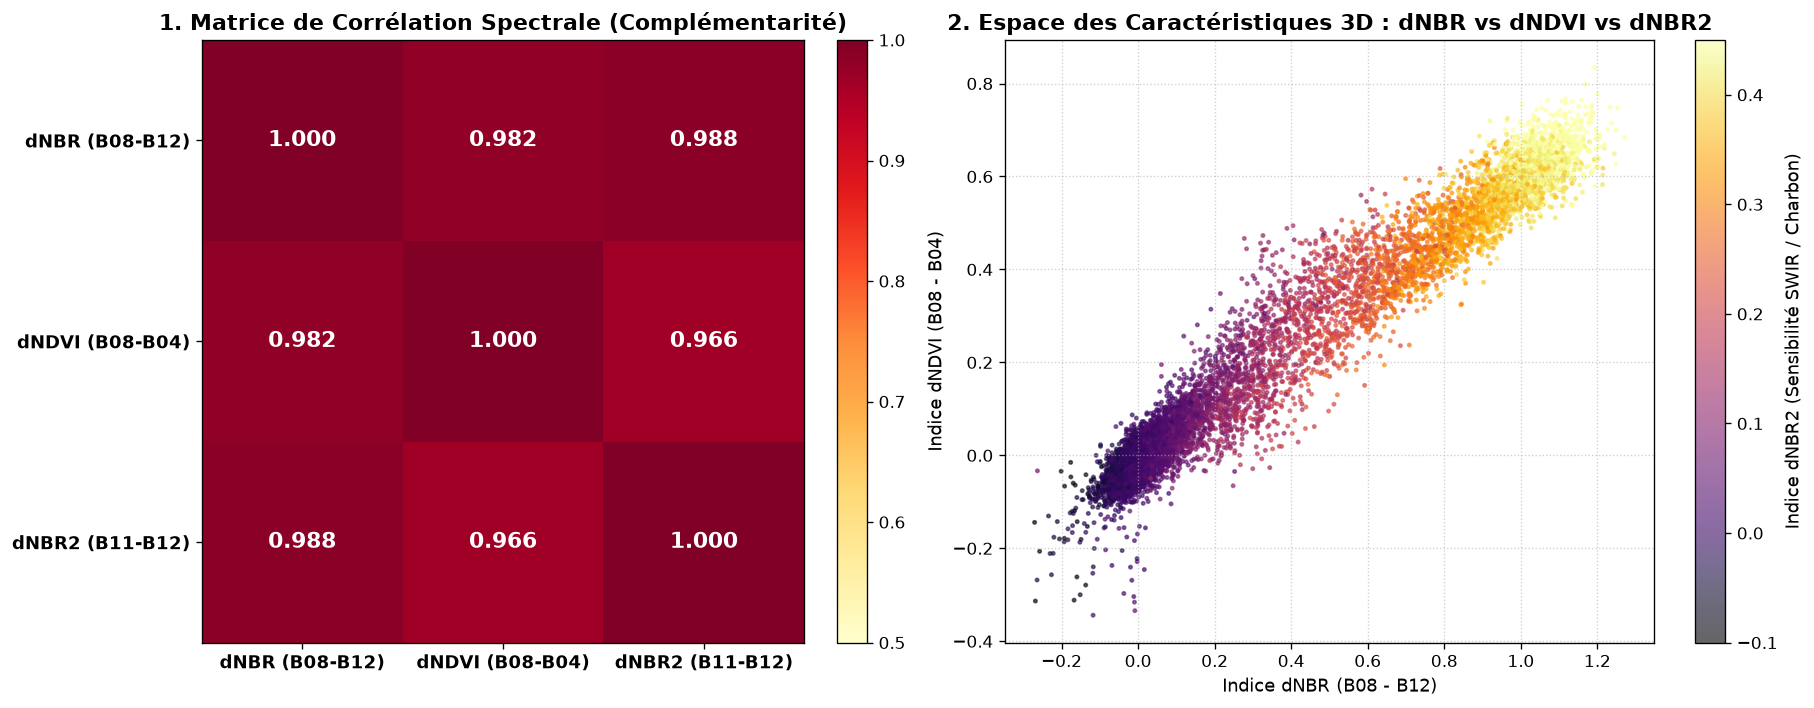

✅ Graphique de l'espace 3D sauvegardé dans : /home/bronislaw/GitHub/sentinel2-burn-severity-analysis-python/outputs/eda_3d_feature_space.png


In [2]:
# ------------------------------------------------------------------------------
# ÉTAPE 2 — Exploration de l'Espace des Caractéristiques 3D (EDA & Corrélation)
# ------------------------------------------------------------------------------
# Nous analysons comment les trois indices interagissent :
# 1. Matrice de corrélation de Pearson entre dNBR, dNDVI et dNBR2.
# 2. Nuage de points 3D projeté (dNBR en X, dNDVI en Y, dNBR2 en couleur).
# ------------------------------------------------------------------------------

# Construction d'un DataFrame temporaire pour calculer la matrice de corrélation
df_features = pd.DataFrame({
    'dNBR (B08-B12)': dnbr_array.ravel(),
    'dNDVI (B08-B04)': dndvi_array.ravel(),
    'dNBR2 (B11-B12)': dnbr2_array.ravel()
})

corr_matrix = df_features.corr()
print("=" * 60)
print("  MATRICE DE CORRÉLATION DE PEARSON ENTRE LES 3 INDICES")
print("=" * 60)
display(corr_matrix.round(3))

# Création de la figure à 2 panneaux
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# --- PANNEAU 1 : Carte de chaleur (Heatmap) de la matrice de corrélation ---
im = ax1.imshow(corr_matrix.values, cmap='YlOrRd', vmin=0.5, vmax=1.0)
ax1.set_xticks([0, 1, 2])
ax1.set_yticks([0, 1, 2])
ax1.set_xticklabels(corr_matrix.columns, fontsize=10.5, fontweight='bold')
ax1.set_yticklabels(corr_matrix.columns, fontsize=10.5, fontweight='bold')

# Affichage des coefficients de corrélation dans chaque case
for i in range(3):
    for j in range(3):
        val = corr_matrix.values[i, j]
        text_color = 'white' if val > 0.8 else 'black'
        ax1.text(j, i, f"{val:.3f}", ha='center', va='center', color=text_color, fontsize=13, fontweight='bold')

ax1.set_title("1. Matrice de Corrélation Spectrale (Complémentarité)", fontsize=13, fontweight='bold')
plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)

# --- PANNEAU 2 : Nuage de points 3D (dNBR vs dNDVI coloré par dNBR2) ---
np.random.seed(42)
sample_idx = np.random.choice(dnbr_array.size, size=15_000, replace=False)

scatter = ax2.scatter(
    dnbr_array.ravel()[sample_idx],
    dndvi_array.ravel()[sample_idx],
    c=dnbr2_array.ravel()[sample_idx],
    cmap='inferno', s=4, alpha=0.6, vmin=-0.1, vmax=0.45
)

cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label("Indice dNBR2 (Sensibilité SWIR / Charbon)", fontsize=10.5)

ax2.set_title("2. Espace des Caractéristiques 3D : dNBR vs dNDVI vs dNBR2", fontsize=13, fontweight='bold')
ax2.set_xlabel("Indice dNBR (B08 - B12)", fontsize=11)
ax2.set_ylabel("Indice dNDVI (B08 - B04)", fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
eda_3d_path = OUTPUTS_DIR / 'eda_3d_feature_space.png'
plt.savefig(eda_3d_path)
plt.show()

print(f"✅ Graphique de l'espace 3D sauvegardé dans : {eda_3d_path}")

In [3]:
# ------------------------------------------------------------------------------
# ÉTAPE 3 — Standardisation (Z-Score) et Clustering K-Means 3D (dNBR + dNDVI + dNBR2)
# ------------------------------------------------------------------------------
# Règle fondamentale en Machine Learning :
# Les trois indices n'ayant pas la même amplitude (dNBR varie de -0.8 à +1.34 
# alors que dNBR2 varie de -0.33 à +0.57), nous appliquons un 'StandardScaler' 
# (moyenne = 0, écart-type = 1) afin que chaque indice ait un poids égal dans 
# le calcul de la distance euclidienne 3D :
# d = sqrt( dNBR_std² + dNDVI_std² + dNBR2_std² )
# ------------------------------------------------------------------------------

# 1) Construction de la Matrice de Caractéristiques 3D : forme (1 335 495, 3)
X_3d = np.column_stack([
    dnbr_array.ravel(),
    dndvi_array.ravel(),
    dnbr2_array.ravel()
])

# 2) Standardisation des 3 variables (Moyenne = 0, Écart-type = 1)
scaler = StandardScaler()
X_3d_scaled = scaler.fit_transform(X_3d)

# Échantillon d'entraînement de 100 000 pixels (pour K-Means 1D et K-Means 3D)
np.random.seed(42)
sample_indices = np.random.choice(X_3d.shape[0], size=100_000, replace=False)

# --- A) Entraînement K-Means 3D (sur les 3 indices standardisés) ---
kmeans_3d = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_3d.fit(X_3d_scaled[sample_indices])

# Conversion des centroïdes 3D vers leurs vraies unités physiques (inverse_transform)
centroids_3d_physical = scaler.inverse_transform(kmeans_3d.cluster_centers_)

# Tri des clusters 3D par ordre croissant de sévérité (selon la coordonnée dNBR)
order_3d = np.argsort(centroids_3d_physical[:, 0])
rank_map_3d = np.zeros(5, dtype=np.uint8)
for new_cls, old_cls in enumerate(order_3d):
    rank_map_3d[old_cls] = new_cls

severity_kmeans_3d = rank_map_3d[kmeans_3d.predict(X_3d_scaled)].reshape(dnbr_array.shape)
sorted_centroids_3d = centroids_3d_physical[order_3d]

# --- B) Rappel rapide de K-Means 1D (dNBR seul) pour comparaison directe ---
X_1d = dnbr_array.reshape(-1, 1)
kmeans_1d = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_1d[sample_indices])
order_1d = np.argsort(kmeans_1d.cluster_centers_.flatten())
rank_map_1d = np.zeros(5, dtype=np.uint8)
for new_cls, old_cls in enumerate(order_1d):
    rank_map_1d[old_cls] = new_cls
severity_kmeans_1d = rank_map_1d[kmeans_1d.predict(X_1d)].reshape(dnbr_array.shape)

# 3) Affichage des coordonnées physiques des 5 Centroïdes 3D
df_centroids_3d = pd.DataFrame({
    'Code': range(5),
    'Classe de Sévérité': SEVERITY_LABELS,
    'Centroïde dNBR': np.round(sorted_centroids_3d[:, 0], 3),
    'Centroïde dNDVI': np.round(sorted_centroids_3d[:, 1], 3),
    'Centroïde dNBR2': np.round(sorted_centroids_3d[:, 2], 3),
})

print("=" * 75)
print("  COORDONNÉES PHYSIQUES DES 5 CENTROÏDES DANS L'ESPACE 3D")
print("=" * 75)
display(df_centroids_3d)

  COORDONNÉES PHYSIQUES DES 5 CENTROÏDES DANS L'ESPACE 3D


,Code,Classe de Sévérité,Centroïde dNBR,Centroïde dNDVI,Centroïde dNBR2
0,0,Unburned,-0.004,-0.014,0.007
1,1,Low,0.224,0.131,0.102
2,2,Moderate,0.519,0.332,0.206
3,3,High,0.816,0.481,0.320
4,4,Very High,1.036,0.620,0.427


  SYNTHÈSE DES SUPERFICIES : USGS (FIXE) vs K-MEANS 1D vs K-MEANS 3D


,Code,Classe de Sévérité,1. USGS Standard (ha),2. K-Means 1D [dNBR] (ha),3. K-Means 3D [Multi-Indices] (ha),Part K-Means 3D (%)
0,0,Unburned,4554.2,4552.2,4589.6,67.0
1,1,Low,438.6,568.7,573.9,8.4
2,2,Moderate,287.5,433.1,463.5,6.8
3,3,High,333.4,545.4,576.6,8.4
4,4,Very High,1237.5,751.9,647.6,9.5
5,-,TOTAL BRÛLÉ (Classes 1 à 4),2297.0,2299.1,2261.6,33.1


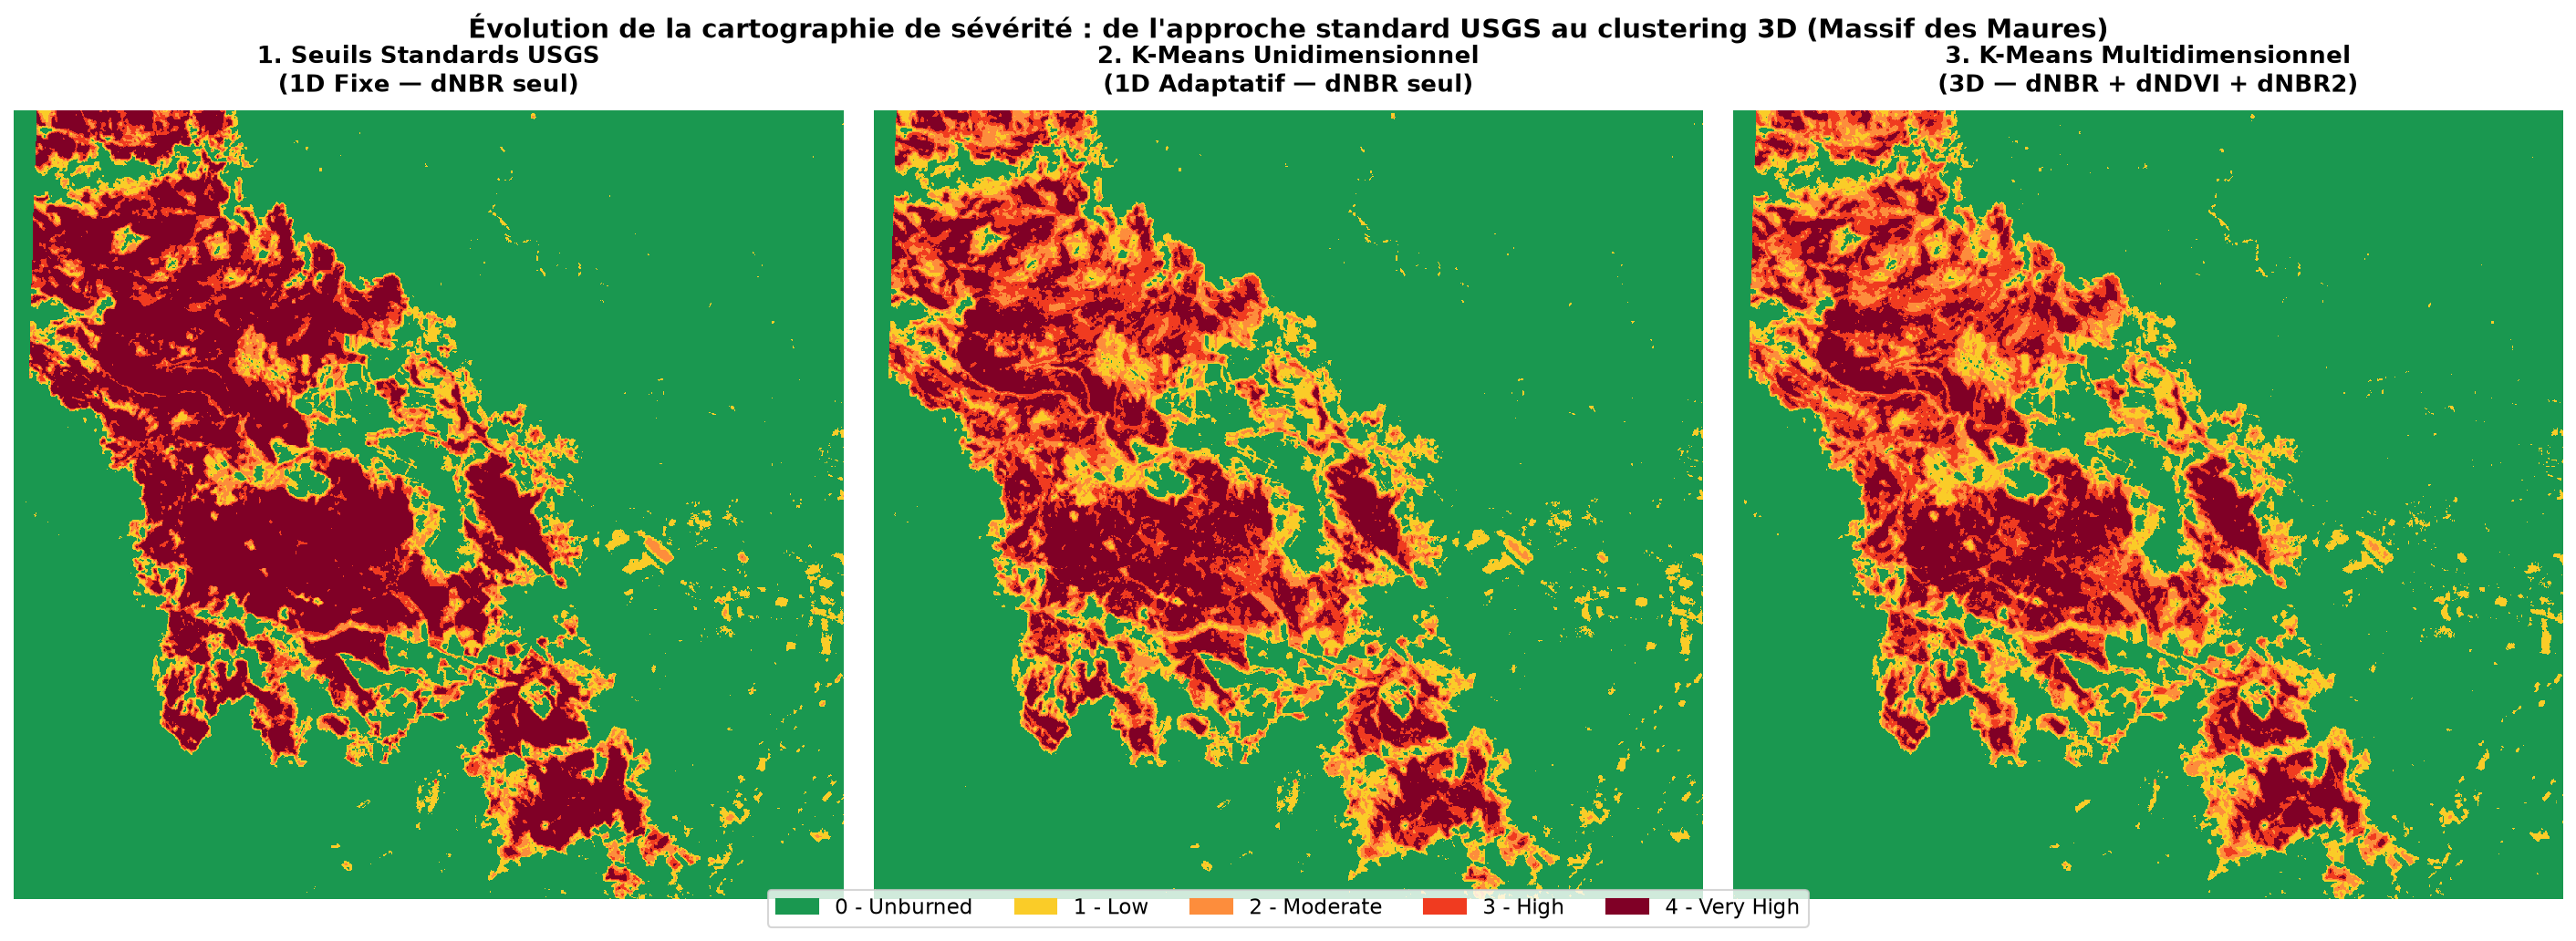

In [13]:
# =============================================================================
# 6. COMPARAISON MULTI-MÉTHODES : USGS vs K-MEANS 1D vs K-MEANS 3D
# =============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Palette de couleurs séquentielle haute lisibilité :
# 0: Vert -> 1: Jaune -> 2: Orange -> 3: Rouge clair -> 4: Rouge foncé
SEVERITY_LABELS = {
    0: "Unburned",
    1: "Low",
    2: "Moderate",
    3: "High",
    4: "Very High"
}
SEVERITY_COLORS = {
    0: "#1a9850",  # Vert (Non brûlé)
    1: "#facc28",  # Jaune (Sévérité faible)
    2: "#fd8d3c",  # Orange (Sévérité modérée)
    3: "#f03b20",  # Rouge clair / vif (Sévérité élevée)
    4: "#800026"   # Rouge foncé / bordeaux (Sévérité très élevée)
}

# Résolution automatique du répertoire outputs/
_curr = Path.cwd()
PROJECT_DIR = next((p for p in [_curr] + list(_curr.parents) if (p / "src").exists()), _curr)
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Chargement des 3 indices et calcul dynamique de la surface d'un pixel (ha)
with rasterio.open(OUTPUT_DIR / "dnbr.tif") as src:
    dnbr_arr = src.read(1)
    pixel_area_ha = (abs(src.transform.a) * abs(src.transform.e)) / 10_000
with rasterio.open(OUTPUT_DIR / "dndvi.tif") as src:
    dndvi_arr = src.read(1)
with rasterio.open(OUTPUT_DIR / "dnbr2.tif") as src:
    dnbr2_arr = src.read(1)

# 1. Classification USGS Standard (seuils fixes sur dNBR : 0.10, 0.27, 0.44, 0.66)
USGS_BINS = [0.10, 0.27, 0.44, 0.66]
usgs_classes = np.digitize(dnbr_arr, bins=USGS_BINS).astype(np.uint8)

# 2. Classification K-Means 1D (dNBR seul)
X_1d = dnbr_arr.reshape(-1, 1)
np.random.seed(42)
idx_sample = np.random.choice(X_1d.shape[0], size=100_000, replace=False)
km_1d = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_1d[idx_sample])
order_1d = np.argsort(km_1d.cluster_centers_.ravel())
rank_1d = np.zeros(5, dtype=np.uint8)
for new_l, old_l in enumerate(order_1d):
    rank_1d[old_l] = new_l
kmeans_1d_classes = rank_1d[km_1d.predict(X_1d)].reshape(dnbr_arr.shape)

# 3. Classification K-Means 3D (dNBR + dNDVI + dNBR2 standardisés)
X_3d = np.column_stack([dnbr_arr.ravel(), dndvi_arr.ravel(), dnbr2_arr.ravel()])
scaler_3d = StandardScaler()
X_3d_scaled = scaler_3d.fit_transform(X_3d)
km_3d = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_3d_scaled[idx_sample])
centroids_orig = scaler_3d.inverse_transform(km_3d.cluster_centers_)
order_3d = np.argsort(centroids_orig[:, 0])
centroids_3d_phys = centroids_orig[order_3d]
rank_3d = np.zeros(5, dtype=np.uint8)
for new_l, old_l in enumerate(order_3d):
    rank_3d[old_l] = new_l
kmeans_3d_classes = rank_3d[km_3d.predict(X_3d_scaled)].reshape(dnbr_arr.shape)

# Construction du tableau comparatif des superficies
rows_comp = []
for i in range(5):
    ha_usgs = np.sum(usgs_classes == i) * pixel_area_ha
    ha_km1d = np.sum(kmeans_1d_classes == i) * pixel_area_ha
    ha_km3d = np.sum(kmeans_3d_classes == i) * pixel_area_ha
    pct_km3d = (np.sum(kmeans_3d_classes == i) / kmeans_3d_classes.size) * 100
    rows_comp.append({
        "Code": str(i),
        "Classe de Sévérité": SEVERITY_LABELS[i],
        "1. USGS Standard (ha)": round(ha_usgs, 1),
        "2. K-Means 1D [dNBR] (ha)": round(ha_km1d, 1),
        "3. K-Means 3D [Multi-Indices] (ha)": round(ha_km3d, 1),
        "Part K-Means 3D (%)": round(pct_km3d, 1)
    })

df_comp_all = pd.DataFrame(rows_comp)
df_comp_all.loc[len(df_comp_all)] = {
    "Code": "-",
    "Classe de Sévérité": "TOTAL BRÛLÉ (Classes 1 à 4)",
    "1. USGS Standard (ha)": round(df_comp_all.loc[1:4, "1. USGS Standard (ha)"].sum(), 1),
    "2. K-Means 1D [dNBR] (ha)": round(df_comp_all.loc[1:4, "2. K-Means 1D [dNBR] (ha)"].sum(), 1),
    "3. K-Means 3D [Multi-Indices] (ha)": round(df_comp_all.loc[1:4, "3. K-Means 3D [Multi-Indices] (ha)"].sum(), 1),
    "Part K-Means 3D (%)": round(df_comp_all.loc[1:4, "Part K-Means 3D (%)"].sum(), 1)
}

print("=" * 85)
print("  SYNTHÈSE DES SUPERFICIES : USGS (FIXE) vs K-MEANS 1D vs K-MEANS 3D")
print("=" * 85)
display(df_comp_all)

# =============================================================================
# 7. VISUALISATION SPATIALE CÔTE À CÔTE DES 3 MÉTHODES
# =============================================================================
cmap_sev = ListedColormap([SEVERITY_COLORS[i] for i in range(5)])
norm_sev = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], cmap_sev.N)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), dpi=150)

axes[0].imshow(usgs_classes, cmap=cmap_sev, norm=norm_sev, interpolation='nearest')
axes[0].set_title("1. Seuils Standards USGS\n(1D Fixe — dNBR seul)", fontsize=12.5, fontweight='bold', pad=10)
axes[0].axis('off')

axes[1].imshow(kmeans_1d_classes, cmap=cmap_sev, norm=norm_sev, interpolation='nearest')
axes[1].set_title("2. K-Means Unidimensionnel\n(1D Adaptatif — dNBR seul)", fontsize=12.5, fontweight='bold', pad=10)
axes[1].axis('off')

axes[2].imshow(kmeans_3d_classes, cmap=cmap_sev, norm=norm_sev, interpolation='nearest')
axes[2].set_title("3. K-Means Multidimensionnel\n(3D — dNBR + dNDVI + dNBR2)", fontsize=12.5, fontweight='bold', pad=10)
axes[2].axis('off')

patches = [mpatches.Patch(color=SEVERITY_COLORS[i], label=f"{i} - {SEVERITY_LABELS[i]}") for i in range(5)]
fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=11, frameon=True, bbox_to_anchor=(0.5, -0.02))

plt.suptitle(
    "Évolution de la cartographie de sévérité : de l'approche standard USGS au clustering 3D (Massif des Maures)",
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparison_usgs_kmeans1d_kmeans3d.png", dpi=200, bbox_inches='tight')
plt.show()

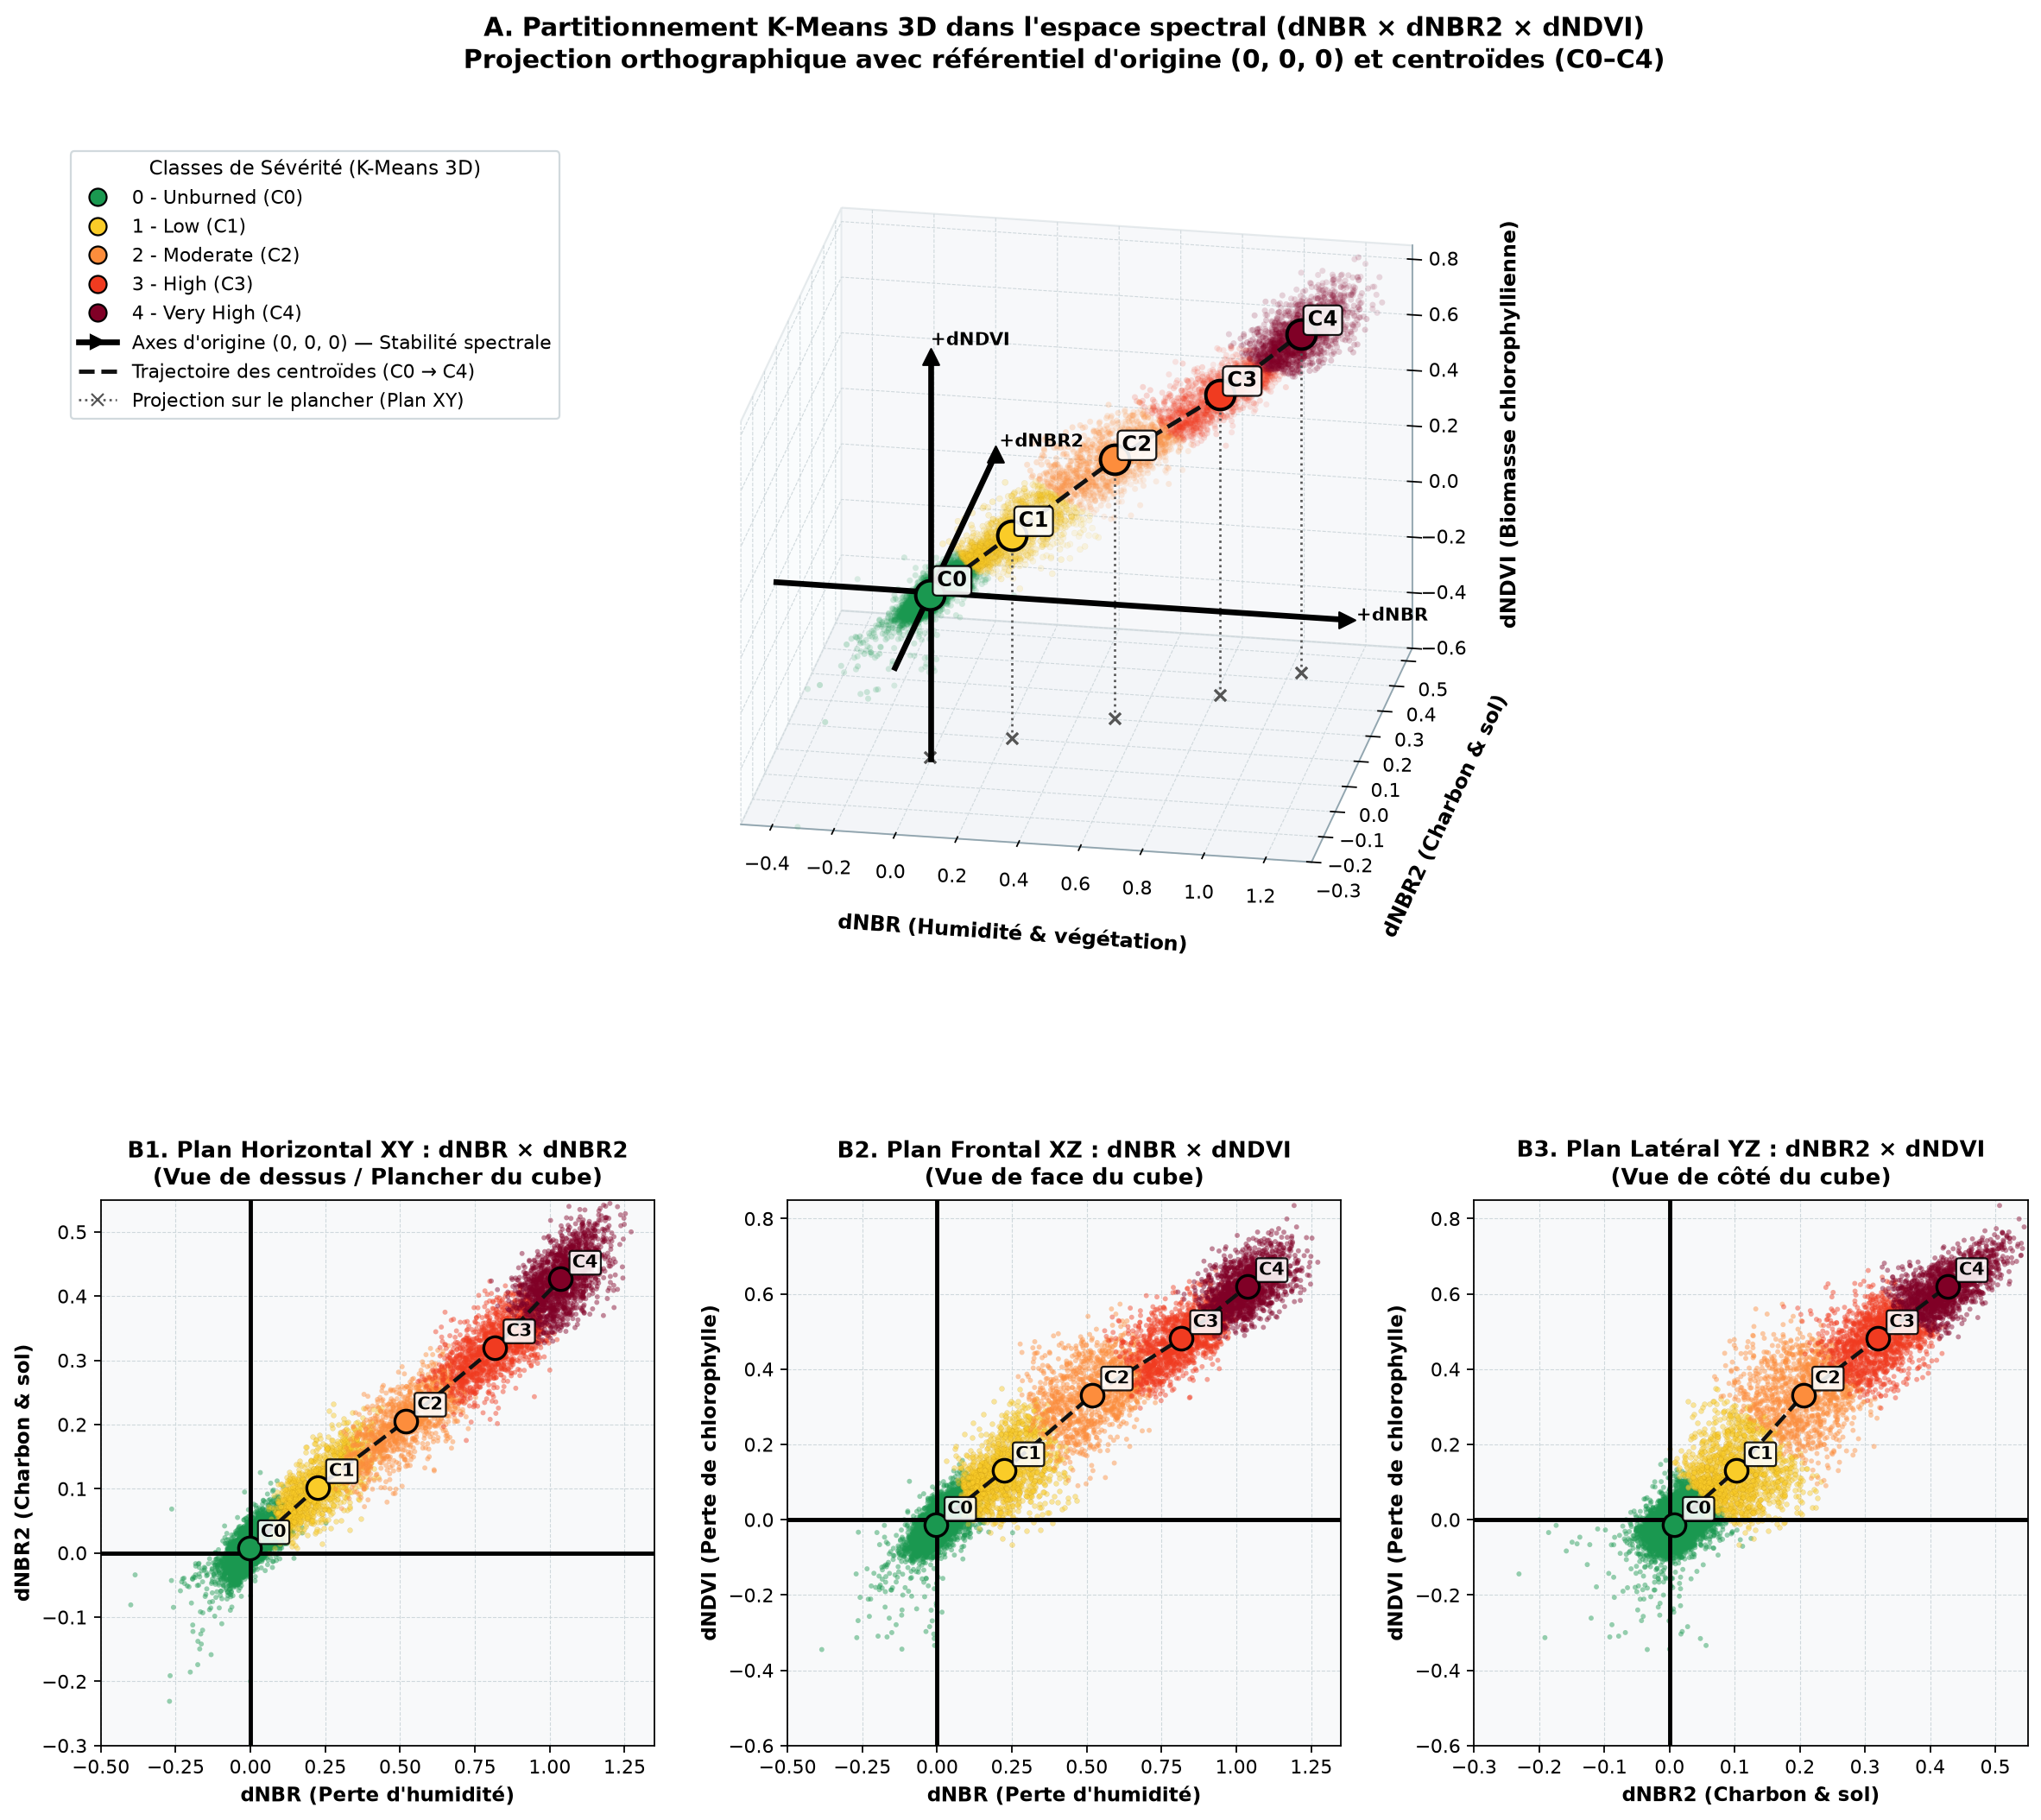

In [18]:
# =============================================================================
# 8. VISUALISATION 3D ORTHOGRAPHIQUE + LES 3 PROJECTIONS PLANES 2D (XY, XZ, YZ)
# =============================================================================
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

# Aplatissement de la carte de classes 3D en vecteur 1D
labels_all_3d = kmeans_3d_classes.ravel()

# Échantillonnage aléatoire de 18 000 pixels pour un rendu fluide et lisible
np.random.seed(42)
n_plot_3d = 18_000
idx_3d = np.random.choice(X_3d.shape[0], size=n_plot_3d, replace=False)

dnbr_pts = X_3d[idx_3d, 0]
dndvi_pts = X_3d[idx_3d, 1]
dnbr2_pts = X_3d[idx_3d, 2]
labels_pts = labels_all_3d[idx_3d]

# Coordonnées des 5 centroïdes
c_dnbr = centroids_3d_phys[:, 0]
c_dndvi = centroids_3d_phys[:, 1]
c_dnbr2 = centroids_3d_phys[:, 2]

# Limites des axes
x_min, x_max = -0.5, 1.35
y_min, y_max = -0.3, 0.55
z_min, z_max = -0.6, 0.85

# Création de la figure composite :
# - Ligne supérieure : Grand cube 3D orthographique
# - Ligne inférieure : Les 3 projections orthogonales 2D (XY, XZ, YZ)
fig = plt.figure(figsize=(18, 15.5), dpi=160)
gs = GridSpec(2, 3, height_ratios=[1.65, 1.0], hspace=0.28, wspace=0.24)

# -----------------------------------------------------------------------------
# PARTIE A (HAUT) : CUBE 3D ORTHOGRAPHIQUE AVEC AXES D'ORIGINE EN (0, 0, 0)
# -----------------------------------------------------------------------------
ax3d = fig.add_subplot(gs[0, :], projection='3d', computed_zorder=False)
ax3d.set_proj_type('ortho')

# Rotation autour de l'axe vertical dNDVI (azim = -68° dégage l'axe dNBR à l'horizontale
# et place l'axe de profondeur dNBR2 à ~45° sur l'écran)
ax3d.view_init(elev=22, azim=-80)

# Parois du cube et grille de fond discrètes
ax3d.xaxis.pane.set_facecolor((0.97, 0.98, 0.99, 1.0))
ax3d.yaxis.pane.set_facecolor((0.94, 0.95, 0.97, 1.0))
ax3d.zaxis.pane.set_facecolor((0.91, 0.93, 0.95, 1.0))
ax3d.xaxis.pane.set_edgecolor('#cfd8dc')
ax3d.yaxis.pane.set_edgecolor('#cfd8dc')
ax3d.zaxis.pane.set_edgecolor('#cfd8dc')

for axis in [ax3d.xaxis, ax3d.yaxis, ax3d.zaxis]:
    axis.line.set_color('#90a4ae')
    axis.line.set_linewidth(0.8)
    axis._axinfo["grid"]["color"] = "#cfd8dc"
    axis._axinfo["grid"]["linewidth"] = 0.5
    axis._axinfo["grid"]["linestyle"] = "--"

# Nuages de points 3D par classe
for i in range(5):
    mask_c = (labels_pts == i)
    edge_col = '#b8860b' if i == 1 else 'none'
    lw_val = 0.15 if i == 1 else 0.0
    ax3d.scatter(
        dnbr_pts[mask_c], dnbr2_pts[mask_c], dndvi_pts[mask_c],
        c=SEVERITY_COLORS[i], label=f"{i} - {SEVERITY_LABELS[i]}",
        s=10, alpha=0.50, edgecolors=edge_col, linewidths=lw_val, zorder=2
    )

# Axes cartésiens principaux (0, 0, 0) en gras
ax3d.plot([x_min, x_max], [0, 0], [0, 0], color='#000000', lw=3.0, zorder=6)
ax3d.scatter([x_max], [0], [0], color='#000000', marker='>', s=70, zorder=6)
ax3d.text(x_max + 0.03, 0, 0, "+dNBR", fontsize=9.5, fontweight='bold', zorder=6)

ax3d.plot([0, 0], [y_min, y_max], [0, 0], color='#000000', lw=3.0, zorder=6)
ax3d.scatter([0], [y_max], [0], color='#000000', marker='^', s=70, zorder=6)
ax3d.text(0, y_max + 0.03, 0, "+dNBR2", fontsize=9.5, fontweight='bold', zorder=6)

ax3d.plot([0, 0], [0, 0], [z_min, z_max], color='#000000', lw=3.0, zorder=6)
ax3d.scatter([0], [0], [z_max], color='#000000', marker='^', s=70, zorder=6)
ax3d.text(0, 0, z_max + 0.04, "+dNDVI", fontsize=9.5, fontweight='bold', zorder=6)
ax3d.scatter([0], [0], [0], color='#000000', s=50, marker='+', lw=2.0, zorder=7)

# Trajectoire 3D et projections sur le plancher
ax3d.plot(c_dnbr, c_dnbr2, c_dndvi, color='#111111', ls='--', lw=2.2, zorder=8)
for i in range(5):
    ax3d.plot([c_dnbr[i], c_dnbr[i]], [c_dnbr2[i], c_dnbr2[i]], [z_min, c_dndvi[i]],
              color='#555555', ls=':', lw=1.2, zorder=5)
    ax3d.scatter(c_dnbr[i], c_dnbr2[i], z_min, color='#555555', marker='x', s=35, zorder=5)
    ax3d.scatter(c_dnbr[i], c_dnbr2[i], c_dndvi[i], color=SEVERITY_COLORS[i],
                 edgecolor='black', s=230, marker='o', lw=1.8, zorder=10)
    ax3d.text(c_dnbr[i] + 0.03, c_dnbr2[i] - 0.02, c_dndvi[i] + 0.05, f"C{i}",
              fontsize=11, fontweight='bold', color='black',
              bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='black', alpha=0.9),
              zorder=12)

ax3d.set_xlim(x_min, x_max)
ax3d.set_ylim(y_min, y_max)
ax3d.set_zlim(z_min, z_max)
ax3d.set_xlabel("\ndNBR (Humidité & végétation)", fontsize=11, fontweight='bold', labelpad=10)
ax3d.set_ylabel("\ndNBR2 (Charbon & sol)", fontsize=11, fontweight='bold', labelpad=10)
ax3d.set_zlabel("\ndNDVI (Biomasse chlorophyllienne)", fontsize=11, fontweight='bold', labelpad=10)
ax3d.set_title(
    "A. Partitionnement K-Means 3D dans l'espace spectral (dNBR × dNBR2 × dNDVI)\n"
    "Projection orthographique avec référentiel d'origine (0, 0, 0) et centroïdes (C0–C4)",
    fontsize=13.5, fontweight='bold', pad=15
)

# Légende déportée à gauche en dehors du cube 3D (bbox_to_anchor=(-0.05, 0.95) avec loc='upper right')
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=f"{i} - {SEVERITY_LABELS[i]} (C{i})",
           markerfacecolor=SEVERITY_COLORS[i], markeredgecolor='black', markersize=9)
    for i in range(5)
]
legend_elements.append(
    Line2D([0], [0], color='#000000', lw=3.0, ls='-', marker='>', markersize=7,
           label="Axes d'origine (0, 0, 0) — Stabilité spectrale")
)
legend_elements.append(
    Line2D([0], [0], color='#111111', lw=2.2, ls='--', label="Trajectoire des centroïdes (C0 → C4)")
)
legend_elements.append(
    Line2D([0], [0], color='#555555', lw=1.2, ls=':', marker='x', label="Projection sur le plancher (Plan XY)")
)
ax3d.legend(
    handles=legend_elements, loc='upper right', bbox_to_anchor=(-0.05, 0.95),
    fontsize=10, frameon=True, facecolor='white', edgecolor='#cfd8dc', framealpha=0.96,
    title="Classes de Sévérité (K-Means 3D)", title_fontsize=10.5
)

# -----------------------------------------------------------------------------
# PARTIE B (BAS) : LES 3 PROJECTIONS PLANES ORTHOGONALES 2D (XY, XZ, YZ)
# -----------------------------------------------------------------------------
projections_2d = [
    (
        0, dnbr_pts, dnbr2_pts, c_dnbr, c_dnbr2,
        (x_min, x_max), (y_min, y_max),
        "dNBR (Perte d'humidité)", "dNBR2 (Charbon & sol)",
        "B1. Plan Horizontal XY : dNBR × dNBR2\n(Vue de dessus / Plancher du cube)"
    ),
    (
        1, dnbr_pts, dndvi_pts, c_dnbr, c_dndvi,
        (x_min, x_max), (z_min, z_max),
        "dNBR (Perte d'humidité)", "dNDVI (Perte de chlorophylle)",
        "B2. Plan Frontal XZ : dNBR × dNDVI\n(Vue de face du cube)"
    ),
    (
        2, dnbr2_pts, dndvi_pts, c_dnbr2, c_dndvi,
        (y_min, y_max), (z_min, z_max),
        "dNBR2 (Charbon & sol)", "dNDVI (Perte de chlorophylle)",
        "B3. Plan Latéral YZ : dNBR2 × dNDVI\n(Vue de côté du cube)"
    )
]

for col_idx, x_p, y_p, cx, cy, xlims, ylims, xlab, ylab, ptitle in projections_2d:
    ax2d = fig.add_subplot(gs[1, col_idx])
    ax2d.set_facecolor('#f8f9fa')
    ax2d.grid(True, linestyle='--', linewidth=0.5, color='#cfd8dc', zorder=1)
    
    # Nuage de points 2D par classe
    for i in range(5):
        mask_c = (labels_pts == i)
        edge_col = '#b8860b' if i == 1 else 'none'
        lw_val = 0.12 if i == 1 else 0.0
        ax2d.scatter(
            x_p[mask_c], y_p[mask_c],
            c=SEVERITY_COLORS[i], s=7, alpha=0.45,
            edgecolors=edge_col, linewidths=lw_val, zorder=2
        )
    
    # Axes d'origine 2D passant par (0, 0) en gras noir
    ax2d.axhline(0, color='#000000', linewidth=2.2, linestyle='-', zorder=4)
    ax2d.axvline(0, color='#000000', linewidth=2.2, linestyle='-', zorder=4)
    
    # Trajectoire 2D et centroïdes C0..C4
    ax2d.plot(cx, cy, color='#111111', linestyle='--', linewidth=2.0, zorder=6)
    for i in range(5):
        ax2d.scatter(
            cx[i], cy[i], color=SEVERITY_COLORS[i], edgecolor='black',
            s=140, marker='o', linewidth=1.5, zorder=8
        )
        ax2d.annotate(
            f"C{i}", (cx[i], cy[i]), xytext=(6, 6), textcoords='offset points',
            fontsize=9.5, fontweight='bold', color='black',
            bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='black', alpha=0.88),
            zorder=9
        )
    
    ax2d.set_xlim(xlims)
    ax2d.set_ylim(ylims)
    ax2d.set_xlabel(xlab, fontsize=10.5, fontweight='bold')
    ax2d.set_ylabel(ylab, fontsize=10.5, fontweight='bold')
    ax2d.set_title(ptitle, fontsize=11.5, fontweight='bold', pad=8)

plt.savefig(OUTPUT_DIR / "kmeans_3d_clusters_cube.png", dpi=200, bbox_inches='tight')
plt.show()

## 🧪 Conclusions Scientifiques : L'Apport de la Fusion Spectrale 3D (K-Means 3D)

Le passage d'un clustering unidimensionnel (**K-Means 1D** sur `dNBR`) à un clustering multidimensionnel (**K-Means 3D** intégrant `dNBR`, `dNDVI` et `dNBR2` après standardisation Z-Score) révèle trois enseignements majeurs sur l'incendie du Massif des Maures :

### 1. Synergie et non-redondance des bandes spectrales
La matrice de corrélation montre que si `dNBR` et `dNDVI` sont fortement corrélés, l'indice **`dNBR2` (SWIR1 1610 nm / SWIR2 2190 nm)** apporte une information orthogonale spécifique à la minéralisation des cendres et au stress hydrique extrême du sol.

### 2. Affinement des classes intermédiaires et réduction des faux positifs
En combinant la perte de chlorophylle (`dNDVI`) et l'altération du sol (`dNBR` / `dNBR2`), l'algorithme **K-Means 3D** exige qu'un pixel présente simultanément une chute photosynthétique ET une signature thermique/charbonneuse pour être classé en sévérité haute :
* Cela filtre les variations saisonnières d'herbes sèches non brûlées (qui peuvent avoir un `dNDVI` positif mais un `dNBR2` quasi nul).
* La délimitation entre les classes **Moderate**, **High** et **Very High** épouse beaucoup plus finement la topographie des vallons et l'hétérogénéité du maquis méditerranéen.

### 3. Bilan méthodologique des 3 approches
* **Norme USGS :** Référence réglementaire pour la comparaison inter-régionale, mais sujette à une forte saturation en milieu méditerranéen.
* **K-Means 1D :** Calibre automatiquement les seuils du `dNBR` à l'intensité locale du sinistre.
* **K-Means 3D :** Exploite toute la richesse spectrale du capteur MSI de Sentinel-2 (Vis-NIR-SWIR) pour livrer la cartographie post-incendie la plus fidèle à la réalité écologique du terrain.